# 01 · Data Exploration and Cleaning

**Project:** Machine learning analysis of foraging behavior in control (C57BL/6J) and Alzheimer's-disease model (APP<sup>NL-G-F</sup>) mice.

## What this notebook does

Before building any model we need to **understand the data**: what every column means, how the experiment was organized, where values are missing and why, and what the behavior looks like across conditions. Mistakes made here (wrong trial order, wrongly filled missing values, leaky predictors) silently spread into every later result.

At the end, this notebook saves one clean table, `data/processed/trials_clean.csv`, that notebooks 02–04 will use.

## One idea to keep in mind throughout: *the mouse is the unit*

The dataset has ~5,700 trials but only **41 mice**. Trials from the same mouse are not independent: a mouse that likes to carry food will do so in many trials. Therefore:

* When we **describe** behavior, we first compute a value **per mouse**, then average across mice. This gives every mouse equal weight, so a mouse with 240 trials does not count 8× more than a mouse with 28 trials.
* We make **no statistical claims** (p-values) from trial-level comparisons here. This notebook is descriptive.

## Structure of each step

For every step you will find: **Goal** (what we do), **Why** (why it matters), the code, **How to read the output**, and **Caveats** where relevant.

## 0. Setup

**Goal:** import the libraries and our own helper code.

The project keeps reusable code in the `src/` folder:
* `src/data_processing.py` – small functions that each perform **one** cleaning step.
* `src/visualization.py` – one shared color scheme and plot style, so that "AD" is always orange and "Eat" is always green in every figure.

`sys.path.insert(0, "..")` tells Python to also look one folder up (the project root), where `src/` lives.

In [1]:
import sys
sys.path.insert(0, "..")   # so that "from src import ..." works from inside notebooks/

import inspect             # used to print the source code of our helper functions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_processing as dp
from src import visualization as viz

viz.set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

RAW_PATH = "../data/raw/foraging_trials.csv"
PROCESSED_PATH = "../data/processed/trials_clean.csv"

## 1. Load the raw data

**Goal:** read the CSV and take a first look.

`dp.load_raw_data` does three small things (printed below):
1. reads the file,
2. stores the original row order in a column `RawRow` — the file is ordered chronologically within each mouse, and that order is the **only** record of which trial came first,
3. converts the date text (`2020_11_20`) into a real date and removes invisible characters from `PelletOrder`.

In [2]:
print(inspect.getsource(dp.load_raw_data))

def load_raw_data(path):
    """Read the raw CSV and keep the original row order in a column.

    The file is already ordered chronologically within each mouse, and
    that order is the only reliable record of which trial came first.
    We store it as `RawRow` so it can always be restored.
    """
    df = pd.read_csv(path)
    df["RawRow"] = np.arange(len(df))
    df["Date"] = pd.to_datetime(df["Trial"], format="%Y_%m_%d")
    # Some PelletOrder strings contain invisible control characters
    # (e.g. '\x03null\x02\x01'). Keep only the visible characters.
    df["PelletOrder"] = df["PelletOrder"].str.replace(r"[^0-9a-z]", "", regex=True)
    return df



In [3]:
raw = dp.load_raw_data(RAW_PATH)

print("Number of rows (trials):", raw.shape[0])
print("Number of columns:      ", raw.shape[1])
raw.head(8)

Number of rows (trials): 5709
Number of columns:       19


,Id,Sex,Status,Trial,PelletOrder,PelletSize,Behavior,Length,Texture,AtFoodArea,BackAndForth,DelayToStart,InboundVel,InitialVelIn,InitialVelOut,OutboundVel,TrialNumber,RawRow,Date
0,3208,Male,AD,2020_11_20,1234,1.0,Eat,short,soft,207.0,0.0,7.500000,10.519737,10.899459,133.247377,17.593750,1.0,0,2020-11-20
1,3208,Male,AD,2020_11_20,1234,2.0,NosePoke,short,soft,770.0,0.0,1.800000,9.636364,11.454751,53.673709,26.285714,2.0,1,2020-11-20
2,3208,Male,AD,2020_11_20,1234,3.0,NosePoke,short,soft,2383.0,1.0,4.166667,12.065217,12.967536,68.734984,28.611111,3.0,2,2020-11-20
3,3208,Male,AD,2020_11_20,1234,4.0,NosePoke,short,soft,5050.0,2.0,4.400000,21.197368,5.718592,35.208611,41.921053,4.0,3,2020-11-20
4,3208,Male,AD,2020_11_23,2314,2.0,NosePoke,short,soft,786.0,4.0,4.366667,22.808219,7.054568,66.408992,33.562500,1.0,4,2020-11-23
5,3208,Male,AD,2020_11_23,2314,3.0,NosePoke,short,soft,2119.0,1.0,3.600000,7.460177,6.175526,62.092299,34.826087,2.0,5,2020-11-23
6,3208,Male,AD,2020_11_23,2314,1.0,Eat,short,soft,284.0,0.0,1.466667,23.820896,18.991705,19.607481,23.450704,3.0,6,2020-11-23
7,3208,Male,AD,2020_11_23,2314,4.0,PartialEat,short,soft,0.0,4.0,2.866667,10.211538,13.188458,51.013662,27.305085,4.0,7,2020-11-23


In [4]:
raw.dtypes

Id                        int64
Sex                         str
Status                      str
Trial                       str
PelletOrder                 str
PelletSize              float64
Behavior                    str
Length                      str
Texture                     str
AtFoodArea              float64
BackAndForth            float64
DelayToStart            float64
InboundVel              float64
InitialVelIn            float64
InitialVelOut           float64
OutboundVel             float64
TrialNumber             float64
RawRow                    int64
Date             datetime64[us]
dtype: object

**How to read the output:**
* Each row is one trial. `Trial` is **not** a trial — it is the **date** of the session (we will fix the naming later).
* `PelletSize` and `TrialNumber` are stored as decimals (`float64`) although they are whole numbers. pandas does this automatically when a numeric column contains missing values (`NaN`), because `NaN` is itself a float.
* There is a `Sex` column that was not in the original column list. We will check that it is balanced between groups.

### 1.1 Two decisions applied immediately

1. **One control group.** The raw `Status` column contains two control labels (`Cont_beh`, `Cont_img`) from two control cohorts. Both are C57BL/6J control mice, so we merge them into `Control`. From here on, every table and figure compares **Control vs AD**.
2. **Mouse 5028, 16 March – 12 April 2021.** In this block the mouse received one pellet size per day, and the recorded pellet order and trial numbers do not match the sizes. The task information for these days is not reliable, so the block is excluded.

Both steps come *before* sessions are reconstructed (section 3), so the excluded block cannot affect session numbering.

In [5]:
print("Status values before:", raw["Status"].unique())
raw = dp.merge_control_cohorts(raw)
print("Status values after: ", raw["Status"].unique())

n_before = len(raw)
raw = dp.drop_mouse_5028_block(raw)
print(f"\nRemoved {n_before - len(raw)} trials of mouse 5028 (16 March - 12 April 2021); {len(raw)} trials remain")

Status values before: <StringArray>
['AD', 'Cont_beh', 'Cont_img']
Length: 3, dtype: str
Status values after:  <StringArray>
['AD', 'Control']
Length: 2, dtype: str

Removed 56 trials of mouse 5028 (16 March - 12 April 2021); 5653 trials remain


## 2. Verify what each column contains

**Goal:** check the values of every column instead of trusting the column names.

**Why:** units, codes and errors in the raw data determine which cleaning steps are needed. For example, if a velocity column contains an artificial maximum value, a model could learn from that artifact.

### 2.1 Categorical columns

In [6]:
for column in ["Status", "Sex", "Behavior", "Length", "Texture", "PelletSize", "TrialNumber"]:
    print("=====", column, "=====")
    print(raw[column].value_counts(dropna=False).to_string())
    print()

===== Status =====
Status
Control    3606
AD         2047

===== Sex =====
Sex
Male      3193
Female    2460

===== Behavior =====
Behavior
Eat           2817
NosePoke       865
Carry          817
NoLeave        471
PartialEat     453
NoApproach     205
NaN             25

===== Length =====
Length
short    3085
long     2568

===== Texture =====
Texture
soft    3805
hard    1848

===== PelletSize =====
PelletSize
1.0    1410
2.0    1410
3.0    1405
4.0    1402
NaN      26

===== TrialNumber =====
TrialNumber
1.0    1385
2.0    1384
3.0    1384
4.0    1384
NaN     107
5.0       7
6.0       1
7.0       1



**How to read the output:**
* `Status` now has two values, `Control` and `AD`. Control has more trials because it has more than twice as many mice.
* `Behavior` has 6 outcomes plus 25 missing labels. As decided: `PartialEat` → `Eat`, and `NoApproach` trials are removed.
* Pellet sizes 1–4 are almost perfectly balanced (~1,400 each), as expected from a design with one pellet of each size per session.
* `TrialNumber` is mostly 1–4; a handful of sessions had 5–7 trials, and 107 values are missing.

### 2.2 Units of the time columns

The column descriptions say `AtFoodArea` is in **video frames**. What about `DelayToStart`? If it was computed from a 30 frames-per-second video, every value should be a whole number of frames, i.e. a multiple of 1/30 s.

In [7]:
delay_in_frames = raw["DelayToStart"] * 30
is_whole_frame = (delay_in_frames - delay_in_frames.round()).abs() < 0.001
print(f"DelayToStart values that are an exact multiple of 1/30 s: {is_whole_frame.mean():.0%}")

raw[["AtFoodArea", "DelayToStart", "BackAndForth"]].describe().round(2)

DelayToStart values that are an exact multiple of 1/30 s: 89%


,AtFoodArea,DelayToStart,BackAndForth
count,5058.00,5056.00,5058.00
mean,1040.43,18.86,0.60
std,1772.25,35.66,1.68
min,0.00,-0.83,0.00
25%,77.00,1.57,0.00
50%,361.50,3.77,0.00
75%,1064.75,16.38,0.00
max,17742.00,315.40,41.00


**How to read the output:** most delays are exact multiples of 1/30 s, so `DelayToStart` is in **seconds**, measured from a 30 fps video. `AtFoodArea` is in **frames** (median ≈ 360 frames ≈ 12 s); we will add a version in seconds (`AtFoodArea_s` = frames / 30).

**Caveat:** about 10 % of delays are not whole frames (maybe from a different timing source or averaging). This does not change the unit, but it is worth confirming the frame rate with the original recording settings.

### 2.3 Velocity columns: is there a ceiling?

A common tracking artifact is a **ceiling**: the software caps unrealistic speeds at a fixed maximum. If that happens, many trials share exactly the same maximum value.

In [8]:
print(raw[dp.VELOCITY_COLUMNS].describe().round(1))
print()
for column in dp.VELOCITY_COLUMNS:
    n_exactly_200 = (raw[column] == 200).sum()
    n_190_to_199 = ((raw[column] >= 190) & (raw[column] < 200)).sum()
    print(f"{column:14s}  trials at exactly 200: {n_exactly_200:3d}   trials between 190 and 199.9: {n_190_to_199}")

       InboundVel  InitialVelIn  InitialVelOut  OutboundVel
count      5053.0        5058.0         5056.0       5056.0
mean         40.3          20.4           28.5         28.4
std          40.2          26.1           26.7         20.3
min           0.2           0.0            0.0          0.0
25%          11.1           6.2           10.6         15.4
50%          23.6          11.4           21.0         24.3
75%          58.7          21.9           37.9         36.4
max         200.0         186.5          200.0        200.0

InboundVel      trials at exactly 200:  47   trials between 190 and 199.9: 7
InitialVelIn    trials at exactly 200:   0   trials between 190 and 199.9: 0
InitialVelOut   trials at exactly 200:  16   trials between 190 and 199.9: 4
OutboundVel     trials at exactly 200:  25   trials between 190 and 199.9: 0


**How to read the output:** dozens of trials have a velocity of exactly **200.0**, but only a few trials fall just below it. A real biological quantity would not pile up on a round number. 200 is therefore a **ceiling** that means "≥ 200 or a tracking glitch". We will treat these values as missing rather than as true speeds.

*Units:* all velocities are in **cm/s** (confirmed by the lab).

### 2.4 Negative latencies

A delay cannot be negative. Let us see how many there are and where they come from.

In [9]:
negative = raw[raw["DelayToStart"] < 0]
print("Trials with DelayToStart < 0:", len(negative))
print("Smallest value:", negative["DelayToStart"].min().round(2), "seconds")
print()
print(negative["Status"].value_counts())

Trials with DelayToStart < 0: 21
Smallest value: -0.83 seconds

Status
Control    21
Name: count, dtype: int64


**How to read the output:** all 21 negative delays are tiny (less than one second) and all come from control mice recorded in 2022. The likely cause is a small timing offset between the gate signal and the video: the mouse started moving a few frames before the gate opening was registered. We will set them to **0** ("started immediately"). Removing these trials would throw away valid behavior, and the error is far smaller than the typical delay.

### 2.5 *When* is each variable measured? (the most important table in this notebook)

To predict a **decision**, a predictor must be **known before the decision is made**. If it is measured during or after the behavior, using it is **target leakage**: the model "predicts" the outcome from its consequences. Example: a mouse that carries food back home has, of course, a different inbound velocity (it runs with food in its mouth), and a mouse that eats at the food spends a long time there.

One trial involves *two* decisions: (1) leave home or not, and (2) once at the food: eat, carry, or only poke.

| Column | Measured when? | Use in a **prospective** model (predict the decision)? |
|---|---|---|
| `Length`, `Texture`, `PelletSize` | set by the experimenter **before** the trial | ✅ yes |
| `TrialInSession`, `SessionNumber` | known before the trial | ✅ yes |
| `PrevBehavior` (previous trial's outcome) | known before the trial | ✅ yes |
| `DelayToStart` | from gate opening until the mouse **leaves** home | ⚠️ not for decision 1: it is undefined for NoLeave and largely *defines* it (time-out). ✅ yes for decision 2 (at the food), on trials where the mouse left |
| `InitialVelOut` | at the start of the trip to the food (before reaching it) | ⚠️ same as `DelayToStart`: ✅ for decision 2 only |
| `OutboundVel` | averaged over **all** outbound trips of the trial, including trips *after* the first food encounter when the mouse goes back and forth | ❌ no: partly measured after the decision |
| `AtFoodArea` | time at the food site, **during** the behavior | ❌ no: eating takes time, so it nearly *defines* Eat |
| `BackAndForth`, `InboundVel`, `InitialVelIn` | **during / after** the eat-carry-poke behavior | ❌ no: consequences of the outcome |
| `Sex` | fixed property of the mouse | possible, but used with care (see notebook 02) |
| `PelletOrder` | the randomized order of sizes within a session | not needed: `PelletSize` and `TrialInSession` already contain this information |

**Consequence for notebook 02:** the 4-class models use only the ✅ rows of decision 1 (task, history, experience). A separate analysis of decision 2 (Eat vs Carry vs NosePoke, on trials where the mouse left) tests whether the *approach* (`DelayToStart`, `InitialVelOut`) adds information. The ❌ variables are not used in any behavior model. Mouse-level summaries of them *within one behavior* (e.g. time at food on Eat trials only) can still describe group differences in notebook 03.

## 3. Study design: animals, sessions and conditions

### 3.1 How many animals per group and sex?

**Why:** the number of *animals* (not trials) limits what we can learn and how we must validate models.

In [10]:
mice = raw.drop_duplicates("Id")[["Id", "Status", "Sex"]]
pd.crosstab(mice["Status"], mice["Sex"], margins=True, margins_name="Total")

Sex,Female,Male,Total
Status,,,
AD,6,7,13
Control,13,15,28
Total,19,22,41


**How to read the output:** 13 AD mice and 28 control mice. Sex is roughly balanced in both groups (6 of 13 AD and 13 of 28 Control mice are female), so sex is unlikely to explain AD vs Control differences. With only 13 AD mice, any per-group estimate for AD will be noisy.

### 3.2 `Trial` is a date, not a session

Each session should contain 4 trials (one per pellet size). Let us count rows per mouse per date.

In [11]:
rows_per_mouse_and_date = raw.groupby(["Id", "Trial"]).size()
print("How many trials does a mouse have on one date?")
print(rows_per_mouse_and_date.value_counts().sort_index().to_string())

How many trials does a mouse have on one date?
3        3
4     1161
5       11
8      114
9        1
12       2


**How to read the output:** most mouse-dates have 4 trials, but over 100 have **8** (two sessions on the same day) and two have 12. So we need a proper **session** identifier. This matters for two reasons:
1. "Previous behavior" must come from the previous trial **in the same session**, not from a different session.
2. The session number measures **experience**, which may change behavior over time.

The function below starts a new session when the mouse or date changes, or when the current session already has ≥ 4 trials and the pellet order changes or the trial number restarts.

In [12]:
print(inspect.getsource(dp.add_session_columns))

def add_session_columns(df):
    """Give every trial a session id, a session number and its position.

    Why this is needed: the column `Trial` is a DATE, not a session.
    Some mice ran two or three sessions on the same day.

    Rule: a new session starts when
      - the mouse changes, or
      - the date changes, or
      - the current session already has >= 4 trials AND either the
        PelletOrder changes or TrialNumber goes back down (a restart).

    New columns:
      SessionId       unique id across the whole dataset
      SessionNumber   1, 2, 3, ... counted separately for each mouse
      TrialInSession  1, 2, 3, ... position of the trial in its session
    """
    df = df.sort_values("RawRow").copy()

    session_ids = []
    session_id = 0
    trials_in_current_session = 0
    previous = None

    for row in df.itertuples():
        start_new = False
        if previous is None:
            start_new = True
        elif row.Id != previous.Id or row.Trial != previous.

In [13]:
raw = dp.add_session_columns(raw)

session_sizes = raw.groupby("SessionId").size()
print("Number of sessions:", raw["SessionId"].nunique())
print("Trials per session:")
print(session_sizes.value_counts().sort_index().to_string())

# Does our reconstructed position agree with the recorded TrialNumber?
has_number = raw["TrialNumber"].notna()
agreement = (raw.loc[has_number, "TrialInSession"] == raw.loc[has_number, "TrialNumber"]).mean()
print(f"\nTrialInSession equals the recorded TrialNumber in {agreement:.1%} of trials")

Number of sessions: 1410
Trials per session:
3       3
4    1393
5      13
7       1

TrialInSession equals the recorded TrialNumber in 99.9% of trials


**How to read the output:** almost all sessions have exactly 4 trials, and the reconstructed position agrees with the recorded `TrialNumber` in nearly all trials. The few disagreements are typing errors in `TrialNumber` (e.g. two trials both numbered "1"). Our `TrialInSession` has two advantages: it is always consistent with the row order, and it also exists for the ~100 trials where `TrialNumber` is missing.

### 3.3 Is pellet size mixed up with trial position?

**Why:** if the largest pellet were always offered last, we could not tell whether behavior depends on *size* or on *being the 4th trial* (e.g. fatigue or satiety). These two variables would be **confounded**.

In [14]:
pd.crosstab(raw["TrialInSession"], raw["PelletSize"])

PelletSize,1.0,2.0,3.0,4.0
TrialInSession,,,,
1,410,386,327,287
2,271,408,378,328
3,404,432,236,337
4,316,184,460,447
5,8,0,4,2
6,1,0,0,0
7,0,0,0,1


**How to read the output:** every pellet size appears at every position, because the order was randomized (`PelletOrder` has 23 different orders). The table is not perfectly flat (for example size 2 is less often in position 4), so size and position are **mildly** correlated, but the two effects can be separated.

### 3.4 Which conditions did each mouse experience?

**Goal:** count trials per mouse in each combination of distance × texture.

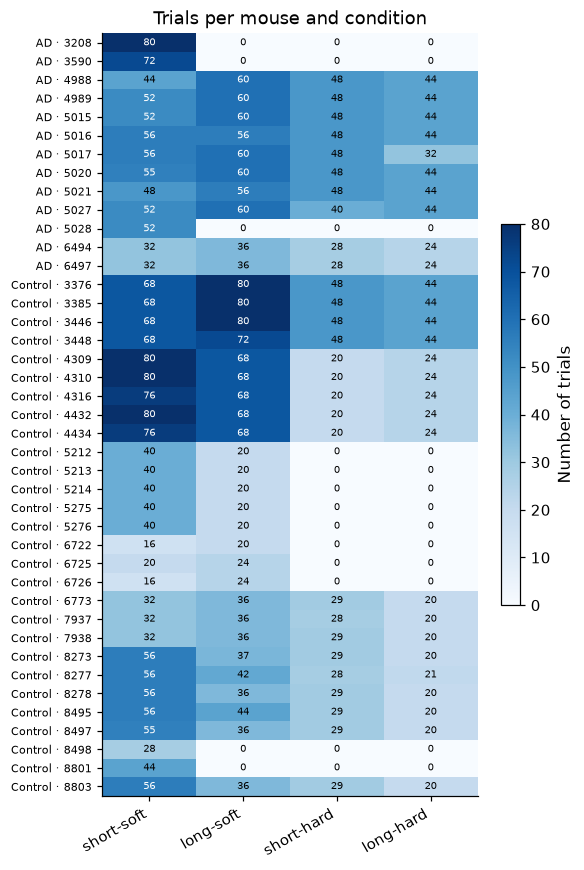

Mice that experienced HARD food:
         with hard food  total mice
Status                             
AD                   10          13
Control              18          28


In [15]:
raw["Condition"] = raw["Length"] + "-" + raw["Texture"]

coverage = pd.crosstab([raw["Status"], raw["Id"]], raw["Condition"])
coverage = coverage[viz.CONDITION_ORDER]   # same column order everywhere

fig, ax = plt.subplots(figsize=(5.5, 9))
image = ax.imshow(coverage.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(coverage.columns)))
ax.set_xticklabels(coverage.columns, rotation=30, ha="right")
row_labels = [f"{status} · {mouse_id}" for status, mouse_id in coverage.index]
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=7)
ax.grid(False)
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        value = coverage.values[i, j]
        text_color = "white" if value > 50 else "black"
        ax.text(j, i, value, ha="center", va="center", fontsize=6.5, color=text_color)
ax.set_title("Trials per mouse and condition")
fig.colorbar(image, ax=ax, label="Number of trials", shrink=0.5)
viz.save_figure(fig, "01_condition_coverage")
plt.show()

n_mice_with_hard = (coverage[["short-hard", "long-hard"]].sum(axis=1) > 0).groupby(level="Status").sum()
n_mice_total = coverage.groupby(level="Status").size()
print("Mice that experienced HARD food:")
print(pd.DataFrame({"with hard food": n_mice_with_hard, "total mice": n_mice_total}))

**How to read the output:** the design is **not balanced**. 13 of the 41 mice never received hard food (3 AD, 10 Control), and 4 mice only ever experienced short-soft. (This table counts all raw trials, before cleaning.)

**Why this matters:**
* For **behavior classification**, models learn the texture effect only from mice that experienced hard food.
* For **group classification** (notebook 03), mouse-level features such as "carry rate with hard food" do not exist for every mouse. This is *structural* missingness at the mouse level, and we must design features that are defined for every mouse.

### 3.5 In what order were the conditions presented?

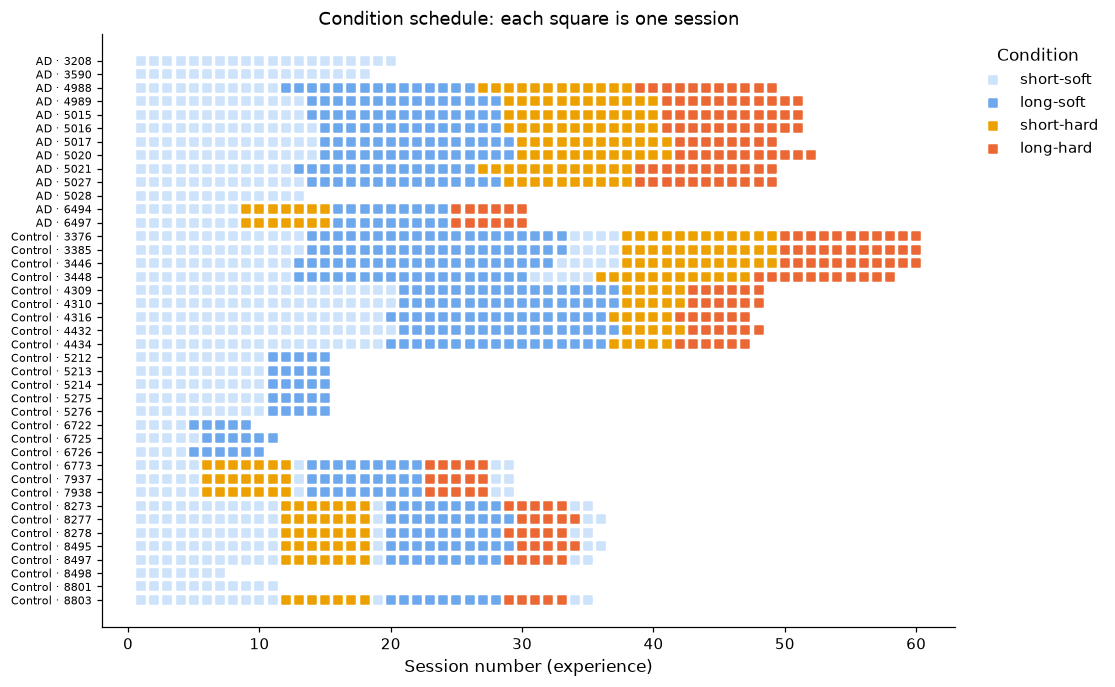

In [16]:
condition_codes = {name: number for number, name in enumerate(viz.CONDITION_ORDER)}
condition_colors = ["#cde2fb", "#6da7ec", "#eda100", "#eb6834"]   # light→dark blue = soft, yellow/orange = hard

sessions = raw.drop_duplicates("SessionId")[["Status", "Id", "SessionNumber", "Condition"]]
mouse_list = coverage.index.get_level_values("Id")

fig, ax = plt.subplots(figsize=(10, 7))
for row_position, mouse_id in enumerate(mouse_list):
    mouse_sessions = sessions[sessions["Id"] == mouse_id]
    for condition, color in zip(viz.CONDITION_ORDER, condition_colors):
        selected = mouse_sessions[mouse_sessions["Condition"] == condition]
        ax.scatter(selected["SessionNumber"], [row_position] * len(selected),
                   color=color, marker="s", s=22, label=condition if row_position == 0 else None)
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Session number (experience)")
ax.set_title("Condition schedule: each square is one session")
ax.grid(False)
ax.legend(title="Condition", bbox_to_anchor=(1.01, 1), loc="upper left")
viz.save_figure(fig, "01_condition_schedule")
plt.show()

**How to read the output:** conditions were given in **blocks** of consecutive sessions, not mixed randomly. Every mouse started with short-soft. After that, two orders were used:
* most mice: short-soft → long-soft → short-hard → long-hard (some Control mice returned to short-soft for a few sessions before hard food),
* the Control mice tested in 2022 and two AD mice (6494, 6497): short-hard came **before** long-soft.

**Why this matters (a confound):** "long-hard" (almost) always came **last**, after many sessions of experience. If mice behave differently in long-hard, we cannot fully separate the *condition* effect from *experience* (learning, habituation, age, or simply the passing of time). Machine learning cannot solve this: it is a property of the experimental design. In notebook 02 we include `SessionInCondition` (how many sessions the mouse has already had in the current condition) to partly account for experience. In all interpretations we will say "**long-hard sessions**", not "**the long-hard condition causes**".

## 4. Missing values: how many, and *why*?

**Goal:** count missing values and find their causes.

**Why:** there are different kinds of missing values, and each needs a different treatment:

* **Structural missingness:** the value *cannot exist*. A mouse that never left home has no outbound velocity. Filling it with 0 would be wrong: 0 cm/s means "moved at zero speed", which is a different claim. It would also leak the label, because "velocity = 0" would simply mean "NoLeave".
* **Ordinary missingness:** the value existed but was not recorded (e.g. a tracking failure). These can be imputed carefully **inside** the model pipeline, using training data only.
* **Missing labels:** without a `Behavior` the trial cannot be used as a training example.

In [17]:
missing_counts = raw.isna().sum()
missing_counts[missing_counts > 0].to_frame("missing values")

,missing values
PelletSize,26
Behavior,25
AtFoodArea,595
BackAndForth,595
DelayToStart,597
InboundVel,600
InitialVelIn,595
InitialVelOut,597
OutboundVel,597
TrialNumber,107


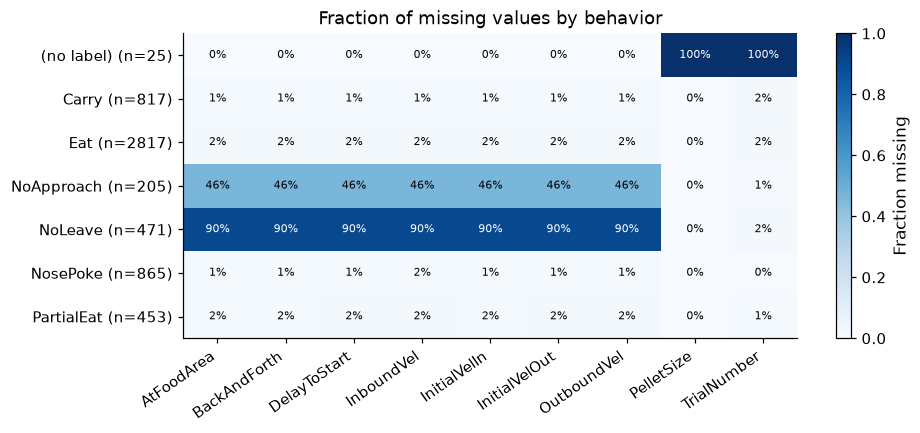

In [18]:
columns_to_check = dp.MOVEMENT_COLUMNS + ["PelletSize", "TrialNumber"]
behavior_labels = raw["Behavior"].fillna("(no label)")
fraction_missing = raw[columns_to_check].isna().groupby(behavior_labels).mean()
trials_per_behavior = behavior_labels.value_counts()

fig, ax = plt.subplots(figsize=(9, 3.6))
image = ax.imshow(fraction_missing.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(columns_to_check)))
ax.set_xticklabels(columns_to_check, rotation=35, ha="right")
ax.set_yticks(range(len(fraction_missing.index)))
ax.set_yticklabels([f"{b} (n={trials_per_behavior[b]})" for b in fraction_missing.index])
ax.grid(False)
for i in range(fraction_missing.shape[0]):
    for j in range(fraction_missing.shape[1]):
        value = fraction_missing.values[i, j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
                color="white" if value > 0.5 else "black")
ax.set_title("Fraction of missing values by behavior")
fig.colorbar(image, ax=ax, label="Fraction missing")
viz.save_figure(fig, "01_missingness_by_behavior")
plt.show()

**How to read the output:**
* **NoLeave:** ~90 % of movement values are missing. This is **structural** (no movement happened).
* **NoApproach:** ~47 % missing (the mouse left but did not reach the food, so some measures are undefined). These trials are removed anyway.
* **Eat / Carry / NosePoke:** only ~2 % missing. This is **ordinary** missingness (tracking problems), spread evenly across behaviors.
* **No label:** these 25 rows also lack `PelletSize`. They come from sessions where the pellet order was recorded as `null`. They are removed.

**But:** about 1 in 10 NoLeave trials *do* have movement values, which should be impossible. Let us look at them.

In [19]:
has_movement_data = raw[dp.MOVEMENT_COLUMNS].notna().any(axis=1)
invalid_noleave = raw[(raw["Behavior"] == "NoLeave") & has_movement_data]
print("NoLeave trials that contain movement data:", len(invalid_noleave))
print("\nDelayToStart in these trials (seconds):")
print(invalid_noleave["DelayToStart"].describe().round(1).to_string())
print("\nNumber of such trials per mouse:")
print(invalid_noleave.groupby(["Status", "Id"]).size().to_string())

NoLeave trials that contain movement data: 45

DelayToStart in these trials (seconds):
count     45.0
mean     167.2
std       85.8
min        1.3
25%      144.3
50%      180.6
75%      243.7
max      315.4

Number of such trials per mouse:
Status   Id  
AD       4988     1
         5016     2
         5017     1
         5020     2
         5021     1
         5028     5
         6494     1
Control  3385    24
         3446     2
         3448     1
         4316     1
         4432     1
         5214     1
         8801     2


**How to read the output:** in most of these trials the "delay to start" is **longer than the 3-minute (180 s) time-out**, which is impossible for a correctly scored NoLeave trial. They are spread over several mice, with one Control mouse contributing many of them. The lab confirmed that these labels are **wrong**, so these trials are removed during cleaning (section 5).

**How we remove them:** we do not simply delete the rows. First we erase their label, and only then compute `PrevBehavior`. The trial that *follows* a removed trial then gets the history `Unknown`, which is honest: we do not know what really happened before it. If we deleted the rows first, the next trial would wrongly appear to follow the trial *before* the removed one.

## 5. Cleaning — in the right order

**Goal:** turn the raw table into a clean analysis table.

**Why the order matters:** `PrevBehavior` (the outcome of the previous trial) must be computed **before** we delete any rows. Suppose trial 2 of a session was a NoApproach trial. If we delete it first, trial 3 would wrongly look like it followed trial 1. So:

1. erase the labels of the invalid NoLeave trials (section 4),
2. pool `PartialEat` into `Eat`,
3. compute `PrevBehavior` on the **complete** sessions,
4. *then* remove unusable trials (NoApproach, unlabeled, invalid NoLeave),
5. fix measurement artifacts,
6. pool pellet sizes into small/large.

(The cohort merge and the removal of the 5028 block were already done in section 1.1.)

We keep a small log of how many trials remain after each step.

In [20]:
print(inspect.getsource(dp.remove_invalid_noleave_labels))
print(inspect.getsource(dp.add_previous_behavior))

def remove_invalid_noleave_labels(df):
    """NoLeave trials that contain movement data are invalid
    (the lab confirmed these labels are wrong).

    We do NOT delete the rows here. Instead we erase their label
    (Behavior -> missing). Two things then happen automatically:
      - add_previous_behavior() gives the NEXT trial the history
        'Unknown', which is honest: we do not know what happened before it.
      - drop_unused_trials() removes these rows, like any unlabeled trial.
    """
    df = df.copy()
    has_movement_data = df[MOVEMENT_COLUMNS].notna().any(axis=1)
    is_invalid = (df["Behavior"] == "NoLeave") & has_movement_data
    df.loc[is_invalid, "Behavior"] = np.nan
    return df

def add_previous_behavior(df):
    """Add the behavior of the previous trial in the SAME session.

    - First trial of a session -> 'SessionStart'
    - Previous trial had no label -> 'Unknown'
    - NoApproach is kept here as a real previous outcome, even though
      NoApproach trial

In [21]:
cleaning_log = []
df = raw.copy()
cleaning_log.append(("Start (after section 1.1)", len(df)))

n_unlabeled_originally = df["Behavior"].isna().sum()
df = dp.remove_invalid_noleave_labels(df)
n_invalid_noleave = df["Behavior"].isna().sum() - n_unlabeled_originally
df = dp.pool_eat_behaviors(df)
df = dp.add_previous_behavior(df)          # BEFORE removing any rows
cleaning_log.append(("After erasing invalid labels / pooling Eat / adding PrevBehavior", len(df)))

n_noapproach = (df["Behavior"] == "NoApproach").sum()
df = dp.drop_unused_trials(df)
cleaning_log.append((f"After removing {n_noapproach} NoApproach, {n_invalid_noleave} invalid NoLeave, "
                     f"{n_unlabeled_originally} unlabeled (+ trials without pellet size)", len(df)))

df = dp.fix_measurement_artifacts(df)
df = dp.add_pellet_size_category(df)
cleaning_log.append(("After fixing artifacts and pooling pellet sizes", len(df)))

pd.DataFrame(cleaning_log, columns=["Step", "Trials remaining"])

,Step,Trials remaining
0,Start (after section 1.1),5653
1,After erasing invalid labels / pooling Eat / a...,5653
2,"After removing 205 NoApproach, 45 invalid NoLe...",5377
3,After fixing artifacts and pooling pellet sizes,5377


**Experience within a condition block.** Because conditions were given in blocks (section 3.5), we also count how many sessions the mouse has already had *in the current condition*: 1 = first day of short-soft, 2 = second day, and so on. `rank(method="dense")` numbers the distinct session numbers 1, 2, 3, … within each mouse × condition.

In [22]:
df["SessionInCondition"] = (
    df.groupby(["Id", "Condition"])["SessionNumber"].rank(method="dense").astype(int)
)

print(inspect.getsource(dp.fix_measurement_artifacts))

def fix_measurement_artifacts(df):
    """Correct known measurement problems in the movement columns.

    1. Negative DelayToStart (21 trials, at most -0.83 s): the mouse
       started moving a few frames before the gate signal was
       registered. Set to 0 = "started immediately".
    2. Velocities (cm/s) of exactly 200 are a tracking ceiling -> set to NaN.
    3. AtFoodArea is recorded in video frames -> add a column in seconds.

    Note: NoLeave trials have no movement values at this point, because
    the invalid NoLeave trials were removed earlier.
    """
    df = df.copy()

    df.loc[df["DelayToStart"] < 0, "DelayToStart"] = 0

    for column in VELOCITY_COLUMNS:
        df.loc[df[column] >= VELOCITY_CEILING, column] = np.nan

    df["AtFoodArea_s"] = df["AtFoodArea"] / FRAMES_PER_SECOND
    return df



In [23]:
print("Groups:   ", df["Status"].value_counts().to_dict())
print("Behaviors:", df["Behavior"].value_counts().to_dict())
print("Sizes:    ", df["SizeCategory"].value_counts().to_dict())
print()
print("Previous behavior (computed before removing trials):")
print(df["PrevBehavior"].value_counts().to_string())

# Sanity check: after cleaning, no NoLeave trial may contain movement data
noleave_rows = df[df["Behavior"] == "NoLeave"]
print("\nNoLeave trials with any movement value:", noleave_rows[dp.MOVEMENT_COLUMNS].notna().any(axis=1).sum())

Groups:    {'Control': 3425, 'AD': 1952}
Behaviors: {'Eat': 3270, 'NosePoke': 865, 'Carry': 817, 'NoLeave': 425}
Sizes:     {'large': 2714, 'small': 2663}

Previous behavior (computed before removing trials):
PrevBehavior
Eat             2480
SessionStart    1355
NosePoke         553
Carry            534
NoLeave          298
NoApproach       109
Unknown           48

NoLeave trials with any movement value: 0


**How to read the output:** we keep ~95 % of the trials. `PrevBehavior` still contains `NoApproach` and `Unknown` as *previous* outcomes. This is correct: the mouse did experience those trials (or we do not know what happened in them), even though they are no longer prediction targets. The final check confirms that NoLeave trials now have **no** movement data, as expected for structurally missing values.

## 6. The final dataset: animals, sessions and class balance

### 6.1 Trials and sessions per mouse

Status             AD  Control
trials   count   13.0     28.0
         mean   150.2    122.3
         std     56.9     66.8
         min     44.0     26.0
         25%    113.0     55.2
         50%    183.0    132.0
         75%    190.0    180.2
         max    204.0    239.0
sessions count   13.0     28.0
         mean    39.4     32.0
         std     14.8     17.5
         min     13.0      7.0
         25%     30.0     15.0
         50%     49.0     35.0
         75%     51.0     47.2
         max     52.0     60.0


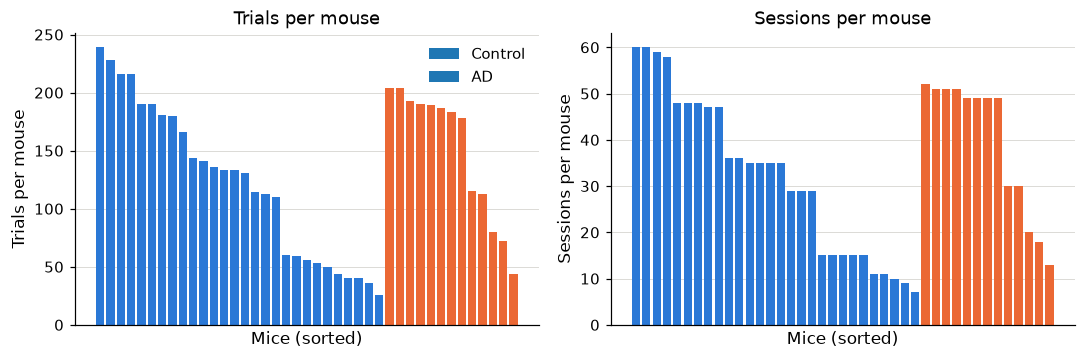

In [24]:
per_mouse = df.groupby(["Status", "Id"]).agg(
    trials=("Behavior", "size"),
    sessions=("SessionId", "nunique"),
).reset_index()

print(per_mouse.groupby("Status")[["trials", "sessions"]].describe().round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, column in zip(axes, ["trials", "sessions"]):
    ordered = per_mouse.sort_values(["Status", column], ascending=[False, False]).reset_index(drop=True)
    colors = [viz.GROUP_COLORS[s] for s in ordered["Status"]]
    ax.bar(range(len(ordered)), ordered[column], color=colors, width=0.8)
    ax.set_xticks([])
    ax.set_xlabel("Mice (sorted)")
    ax.set_ylabel(f"{column.capitalize()} per mouse")
for group in viz.GROUP_ORDER:
    axes[0].bar([], [], color=viz.GROUP_COLORS[group], label=group)
axes[0].legend()
axes[0].set_title("Trials per mouse")
axes[1].set_title("Sessions per mouse")
fig.tight_layout()
viz.save_figure(fig, "01_trials_sessions_per_mouse")
plt.show()

**How to read the output:** the number of trials per mouse varies about 8-fold (from ~30 to ~240). If we pooled all trials, the few heavily-tested mice would dominate every result. This is another reason to compute summaries **per mouse first**.

### 6.2 Class distribution: trial level vs. mouse level

In [25]:
trial_counts = pd.crosstab(df["Status"], df["Behavior"])[viz.BEHAVIOR_ORDER]
trial_percent = pd.crosstab(df["Status"], df["Behavior"], normalize="index")[viz.BEHAVIOR_ORDER] * 100

print("Number of trials:")
print(trial_counts)
print("\nPercentage of trials (pooled over all trials):")
print(trial_percent.round(1))

Number of trials:
Behavior   Eat  Carry  NosePoke  NoLeave
Status                                  
AD        1240    207       298      207
Control   2030    610       567      218

Percentage of trials (pooled over all trials):
Behavior   Eat  Carry  NosePoke  NoLeave
Status                                  
AD        63.5   10.6      15.3     10.6
Control   59.3   17.8      16.6      6.4


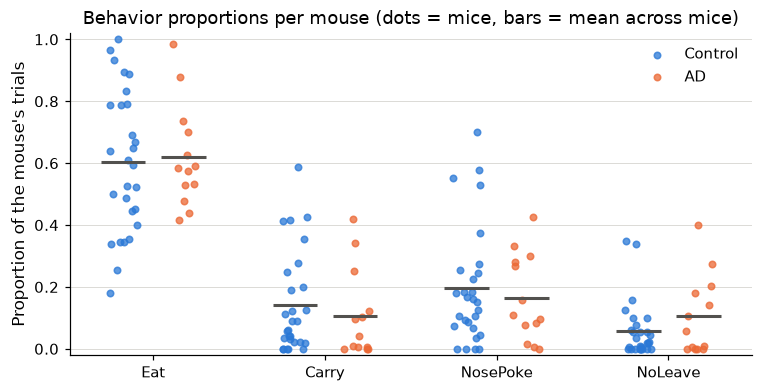

Mean proportion across mice:
Behavior    Eat  Carry  NosePoke  NoLeave
Status                                   
AD        0.621  0.107     0.166    0.106
Control   0.603  0.143     0.196    0.058


In [26]:
# Proportion of each behavior PER MOUSE (each row = one mouse, each row sums to 1)
mouse_proportions = pd.crosstab([df["Status"], df["Id"]], df["Behavior"], normalize="index")
mouse_proportions = mouse_proportions[viz.BEHAVIOR_ORDER].reset_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
rng = np.random.default_rng(0)          # fixed seed: same horizontal jitter every run
for b_index, behavior in enumerate(viz.BEHAVIOR_ORDER):
    for g_index, group in enumerate(viz.GROUP_ORDER):
        values = mouse_proportions.loc[mouse_proportions["Status"] == group, behavior]
        x_center = b_index + (g_index - 0.5) * 0.35
        jitter = rng.uniform(-0.08, 0.08, size=len(values))
        ax.scatter(x_center + jitter, values, s=18, alpha=0.75, color=viz.GROUP_COLORS[group],
                   label=group if b_index == 0 else None)
        ax.hlines(values.mean(), x_center - 0.13, x_center + 0.13, color=viz.NEUTRAL_DARK, linewidth=2)
ax.set_xticks(range(len(viz.BEHAVIOR_ORDER)))
ax.set_xticklabels(viz.BEHAVIOR_ORDER)
ax.set_ylabel("Proportion of the mouse's trials")
ax.set_ylim(-0.02, 1.02)
ax.set_title("Behavior proportions per mouse (dots = mice, bars = mean across mice)")
ax.legend()
viz.save_figure(fig, "01_behavior_proportions_per_mouse")
plt.show()

print("Mean proportion across mice:")
print(mouse_proportions.groupby("Status")[viz.BEHAVIOR_ORDER].mean().round(3))

**How to read the output:**
* **Class imbalance:** Eat is by far the most common outcome (~60 % in both groups). A model that always answers "Eat" would already be right ~60 % of the time, so plain accuracy would be misleading. In notebook 02 we use **balanced accuracy** and **macro-F1**, which weight every class equally.
* **The rare classes differ between groups:** for Control mice NoLeave is rarest (~6 % per mouse); for AD mice Carry and NoLeave are equally rare (~11 % each). AD mice show almost **twice as much NoLeave** (10.6 % vs 5.8 %) and somewhat **less Carry** (10.7 % vs 14.3 %).
* **Between-mouse variability is large:** some mice almost never carry or stay home, others often do. Much of the variation is *between animals*, which is why models must be tested on **unseen mice**.
* The trial-level percentages and the per-mouse means differ a little (e.g. Control Carry 17.8 % vs 14.3 %): mice with many trials carried more, and they dominate the pooled number.

## 7. Behavior across task conditions

**Goal:** see how the probability of each behavior changes with distance, texture and pellet size, separately for the two groups.

**How we compute it:** for each mouse we take the proportion of each behavior within each condition × size cell. Then we average these proportions across the mice that experienced the cell. Error bars show the **standard error of the mean across mice** (SEM = SD / √n<sub>mice</sub>).

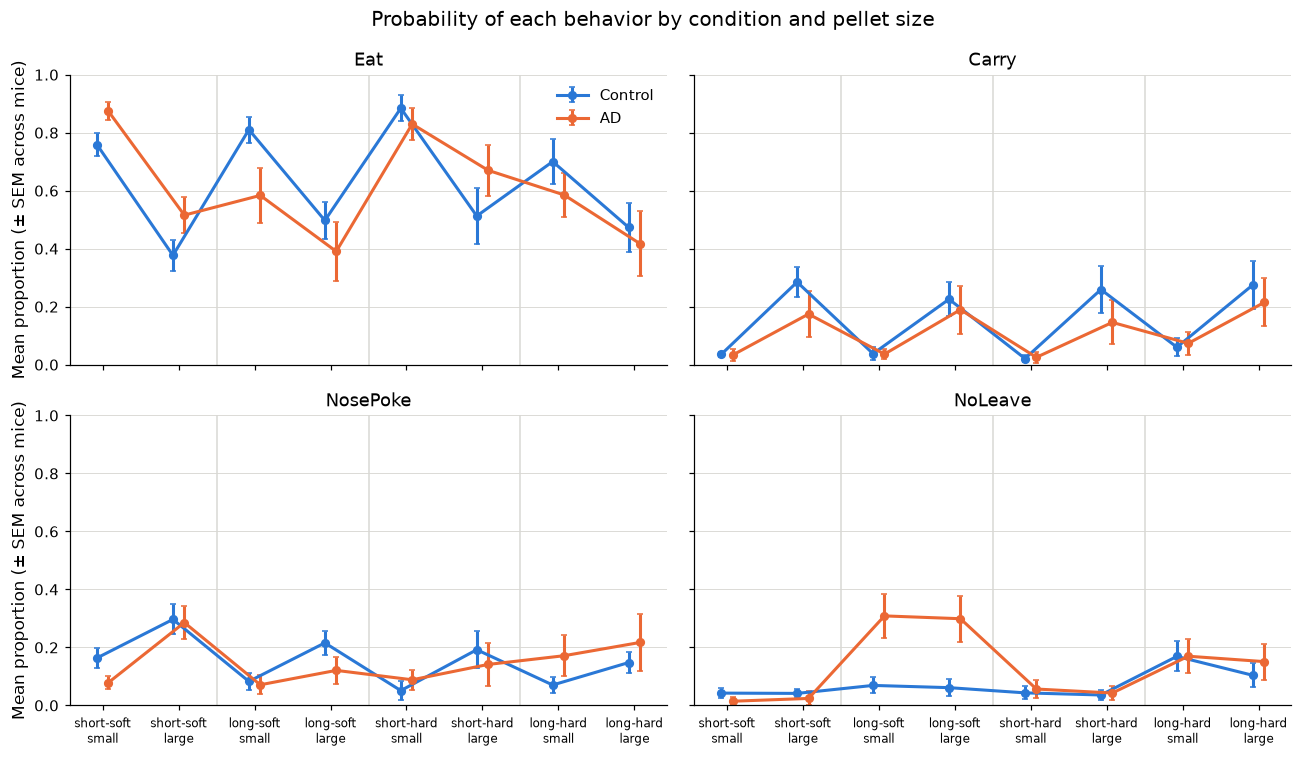

Number of mice contributing to each cell:
Status                   Control  AD
Condition  SizeCategory             
short-soft small              28  13
           large              28  13
long-soft  small              26  10
           large              26  10
short-hard small              18  10
           large              18  10
long-hard  small              18  10
           large              18  10


In [27]:
cell_columns = ["Status", "Id", "Condition", "SizeCategory"]
per_mouse_cell = (
    df.groupby(cell_columns)["Behavior"]
      .value_counts(normalize=True)          # proportion of each behavior within the cell
      .unstack(fill_value=0)                  # one column per behavior
      .reindex(columns=viz.BEHAVIOR_ORDER, fill_value=0)
      .reset_index()
)

summary_mean = per_mouse_cell.groupby(["Status", "Condition", "SizeCategory"])[viz.BEHAVIOR_ORDER].mean()
summary_sem = per_mouse_cell.groupby(["Status", "Condition", "SizeCategory"])[viz.BEHAVIOR_ORDER].sem()
summary_n = per_mouse_cell.groupby(["Status", "Condition", "SizeCategory"]).size()

# the 8 cells in a fixed order: short-soft small, short-soft large, long-soft small, ...
cells = [(condition, size) for condition in viz.CONDITION_ORDER for size in viz.SIZE_ORDER]
cell_labels = [f"{condition}\n{size}" for condition, size in cells]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, behavior in zip(axes.flat, viz.BEHAVIOR_ORDER):
    for g_index, group in enumerate(viz.GROUP_ORDER):
        means = [summary_mean.loc[(group, c, s), behavior] for c, s in cells]
        sems = [summary_sem.loc[(group, c, s), behavior] for c, s in cells]
        x = np.arange(len(cells)) + (g_index - 0.5) * 0.15
        ax.errorbar(x, means, yerr=sems, color=viz.GROUP_COLORS[group], marker="o", markersize=5,
                    linewidth=2, capsize=2, label=group)
    ax.set_title(behavior)
    ax.set_ylim(0, 1)
    for boundary in [1.5, 3.5, 5.5]:
        ax.axvline(boundary, color=viz.NEUTRAL_LIGHT, linewidth=1)
for ax in axes[1]:
    ax.set_xticks(range(len(cells)))
    ax.set_xticklabels(cell_labels, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Mean proportion (± SEM across mice)")
axes[0, 0].legend()
fig.suptitle("Probability of each behavior by condition and pellet size")
fig.tight_layout()
viz.save_figure(fig, "01_behavior_by_condition")
plt.show()

print("Number of mice contributing to each cell:")
print(summary_n.unstack("Status")[viz.GROUP_ORDER].reindex(cells))

**How to read the output:** each panel is one behavior. Read along the x-axis to see how the behavior changes with distance (short → long), texture (soft → hard) and size (small → large). Compare the blue and orange lines to see group differences. Pay attention to the number of mice per cell (printed below the figure): hard-food cells contain fewer mice, so their error bars are wider.

What the figure shows:
* **Pellet size is the strongest task effect, in both groups.** Large pellets are eaten on the spot much less often (e.g. Control short-soft: 76 % → 38 %) and are carried or only nose-poked more often. A large pellet takes longer to eat at the exposed food site, so carrying it home becomes more attractive. Notice the zig-zag pattern in the Eat and Carry panels: it alternates between small and large.
* **Distance and texture have weaker, less consistent effects** on the eat/carry balance.
* **The clearest group difference is NoLeave in long-soft:** about 30 % of AD trials vs ~7 % of Control trials, for both pellet sizes. AD mice also eat less in long-soft. For most mice, long-soft was the **first time the distance changed**. So this may reflect a reaction to the *change* of condition rather than to distance itself. The cell below looks at individual mice.
* Small differences elsewhere (e.g. Carry for large pellets) have overlapping error bars and should not be over-interpreted.

**Caveat:** these are descriptive averages. They do not account for the condition-order confound (section 3.5) or for repeated measures. Formal comparisons belong in the modeling notebooks.

In [28]:
# Is the high NoLeave rate of AD mice in long-soft driven by a few animals or by most of them?
long_soft = df[df["Condition"] == "long-soft"]
noleave_rate = long_soft.groupby(["Status", "Id"])["Behavior"].apply(lambda b: (b == "NoLeave").mean())
for group in viz.GROUP_ORDER:
    rates = noleave_rate[group].sort_values(ascending=False)
    print(f"{group}: NoLeave rate per mouse in long-soft")
    print("  ", " ".join(f"{r:.2f}" for r in rates))

Control: NoLeave rate per mouse in long-soft
   0.63 0.41 0.18 0.09 0.08 0.06 0.06 0.06 0.05 0.03 0.03 0.02 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00
AD: NoLeave rate per mouse in long-soft
   0.62 0.55 0.54 0.48 0.35 0.33 0.11 0.03 0.02 0.00


**How to read the output:** in the AD group the long-soft NoLeave rate is **bimodal**: 6 of the 10 AD mice that experienced long-soft stay home in 33–62 % of long-soft trials, while the rest rarely or never do. Two Control mice show the same pattern (0.63 and 0.41), but most Control mice are near 0. This is an important lesson for the whole project: **"AD vs Control" differences can be driven by a subset of animals**, and with 13 AD mice a group mean can hide real heterogeneity. Mouse-level features such as "NoLeave rate after a condition change" are good candidates for group classification (notebook 03).

## 8. Behavioral history: does the previous trial predict the next one?

**Goal:** estimate P(current behavior | previous behavior in the same session).

**Why:** if behavior is "sticky" (a mouse that just carried tends to carry again), then `PrevBehavior` is a useful **prospective** predictor for notebook 02.

**How we compute it:** within each group we count transitions from previous to current behavior and divide each row by its total. *Caveat:* this pools trials across mice (heavily-tested mice weigh more). It is fine for a first look, but notebook 02 tests the effect properly on held-out mice.

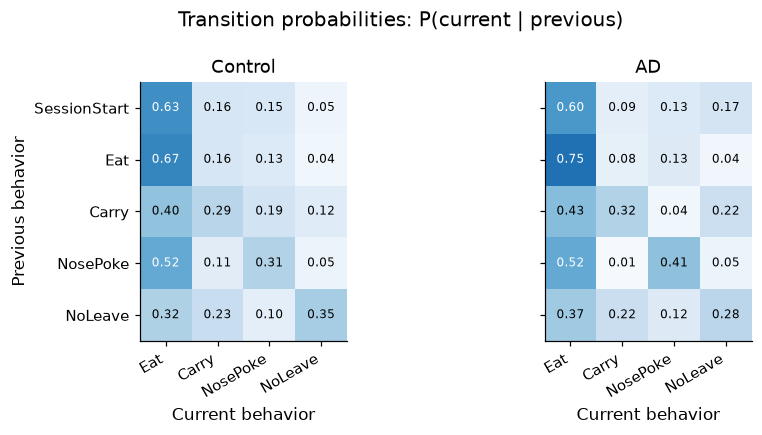

In [29]:
previous_order = ["SessionStart", "Eat", "Carry", "NosePoke", "NoLeave"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, group in zip(axes, viz.GROUP_ORDER):
    group_trials = df[(df["Status"] == group) & df["PrevBehavior"].isin(previous_order)]
    transitions = pd.crosstab(group_trials["PrevBehavior"], group_trials["Behavior"], normalize="index")
    transitions = transitions.reindex(index=previous_order, columns=viz.BEHAVIOR_ORDER, fill_value=0)
    ax.imshow(transitions.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(transitions.shape[0]):
        for j in range(transitions.shape[1]):
            value = transitions.values[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if value > 0.5 else "black")
    ax.set_xticks(range(len(viz.BEHAVIOR_ORDER)))
    ax.set_xticklabels(viz.BEHAVIOR_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(len(previous_order)))
    ax.set_yticklabels(previous_order)
    ax.set_xlabel("Current behavior")
    ax.set_title(group)
    ax.grid(False)
axes[0].set_ylabel("Previous behavior")
fig.suptitle("Transition probabilities: P(current | previous)")
fig.tight_layout()
viz.save_figure(fig, "01_transition_matrix")
plt.show()

**How to read the output:** each row sums to 1. Compare each row with the `SessionStart` row, which is the "no history" baseline.
* **Behaviors repeat.** In both groups the diagonal is higher than the baseline: NosePoke → NosePoke (Control / AD: 0.31 / 0.41 vs baseline 0.15 / 0.13), Carry → Carry (0.29 / 0.32 vs 0.16 / 0.09) and especially NoLeave → NoLeave (0.35 / 0.28 vs 0.05 / 0.17).
* **After a Carry, NoLeave becomes more likely** (0.12 Control, 0.22 AD). A plausible explanation: the mouse is still at home eating the pellet it carried, so it does not come out when the gate opens. This shows that `PrevBehavior` can carry *mechanical* information, not only "preference".
* **AD mice start sessions with NoLeave more often** (0.17 vs 0.05).

**Caveat:** persistence can mean two things. Either it reflects the mouse's *state* within a session (hunger, anxiety), or simply that this *mouse* tends to show that behavior in general (pooling mice mixes the two). A model can use both, but only the first is a true "history" effect. We will keep this in mind when interpreting `PrevBehavior` in notebook 02.

## 9. Experience: does behavior change across sessions?

**Goal:** plot each behavior against the number of sessions already done in the current condition (`SessionInCondition`).

**Why:** if behavior changes with experience, a model that ignores experience will be less accurate, and the condition effects from section 7 may partly be learning effects.

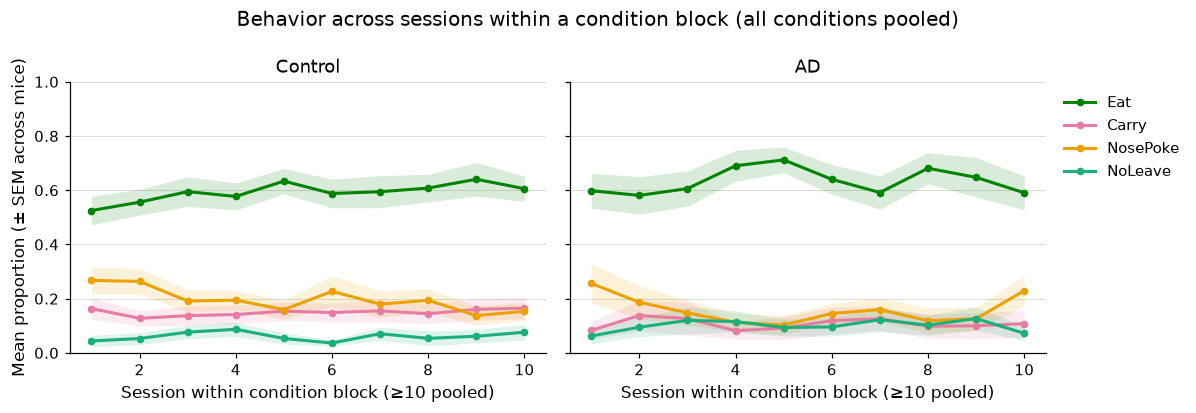

In [30]:
MAX_SESSION = 10   # few mice have more sessions per block; later sessions are pooled into "10"
df_exp = df.copy()
df_exp["SessionInCondition_capped"] = df_exp["SessionInCondition"].clip(upper=MAX_SESSION)

per_mouse_exp = (
    df_exp.groupby(["Status", "Id", "SessionInCondition_capped"])["Behavior"]
          .value_counts(normalize=True).unstack(fill_value=0)
          .reindex(columns=viz.BEHAVIOR_ORDER, fill_value=0).reset_index()
)
exp_mean = per_mouse_exp.groupby(["Status", "SessionInCondition_capped"])[viz.BEHAVIOR_ORDER].mean()
exp_sem = per_mouse_exp.groupby(["Status", "SessionInCondition_capped"])[viz.BEHAVIOR_ORDER].sem()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, group in zip(axes, viz.GROUP_ORDER):
    for behavior in viz.BEHAVIOR_ORDER:
        x = exp_mean.loc[group].index
        y = exp_mean.loc[group, behavior]
        error = exp_sem.loc[group, behavior]
        ax.plot(x, y, color=viz.BEHAVIOR_COLORS[behavior], linewidth=2, marker="o", markersize=4, label=behavior)
        ax.fill_between(x, y - error, y + error, color=viz.BEHAVIOR_COLORS[behavior], alpha=0.15, linewidth=0)
    ax.set_title(group)
    ax.set_xlabel(f"Session within condition block (≥{MAX_SESSION} pooled)")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Mean proportion (± SEM across mice)")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("Behavior across sessions within a condition block (all conditions pooled)")
fig.tight_layout()
viz.save_figure(fig, "01_behavior_by_experience")
plt.show()

**How to read the output:** a flat line means no change with experience. The effects are modest: in both groups **NosePoke decreases** over the first sessions of a block (≈ 0.27 → 0.15–0.20 in Control, → ~0.10 in AD by session 5), and **Eat increases** slightly. Mice seem to "commit" more as a condition becomes familiar. `SessionInCondition` is therefore a reasonable candidate predictor in notebook 02, but it will probably add only a little.

**Caveat:** this pools the four conditions, which were run in a fixed order. Session 1 of long-hard is not the same as session 1 of short-soft, because the mouse is much more experienced overall by then.

## 10. Movement and latency variables

Only two of these variables (`DelayToStart`, `InitialVelOut`) are valid predictors, and only for the food-site decision (section 2.5). We still explore all of them, because:
* mouse-level summaries of them are candidate features for **group classification** (notebook 03),
* we need to find outliers and measurement problems.

### 10.1 Distributions and outliers (trials where the mouse left home)

                count   mean    std   min    25%    50%    75%     max
DelayToStart   4876.0  17.03  30.99  0.00   1.53   3.60  14.90  306.13
AtFoodArea_s   4878.0  35.65  59.78  0.00   2.83  12.75  37.38  591.40
OutboundVel    4852.0  27.78  16.27  0.00  15.65  24.53  36.50  130.85
InboundVel     4827.0  38.66  37.19  0.21  10.99  23.16  57.32  197.54
InitialVelOut  4861.0  28.24  24.99  0.00  10.83  21.26  38.19  199.01
BackAndForth   4878.0   0.58   1.56  0.00   0.00   0.00   0.00   25.00


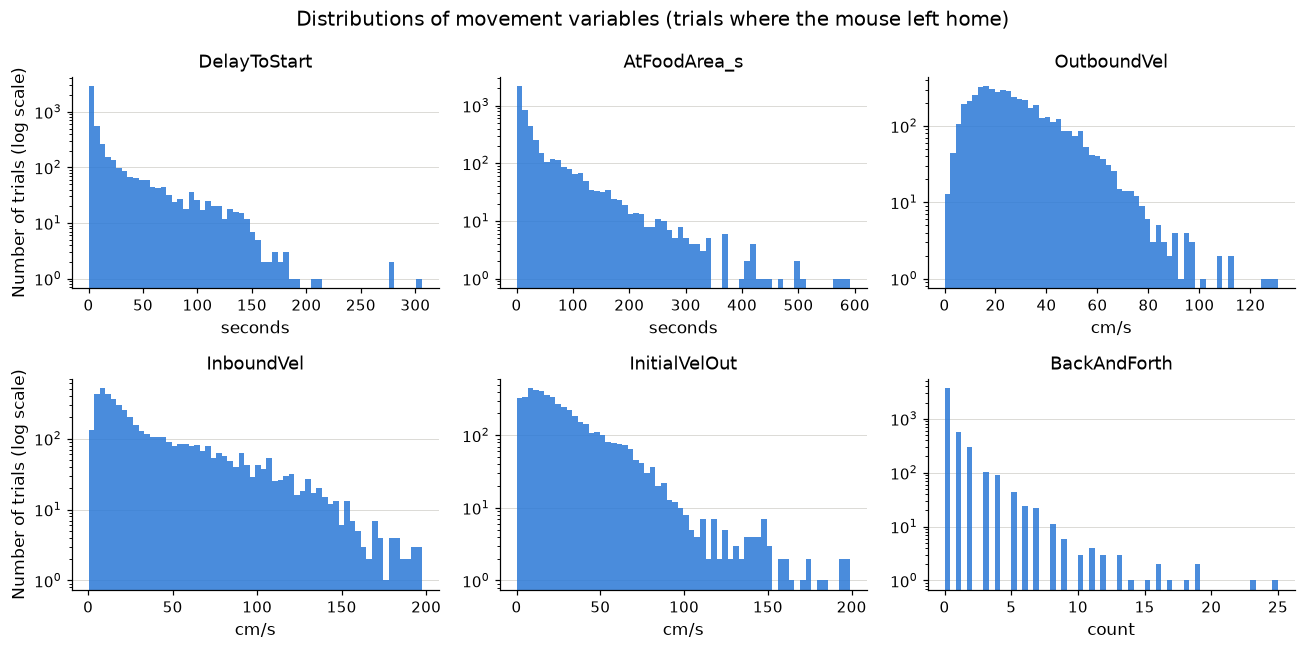

In [31]:
movement_trials = df[df["Behavior"] != "NoLeave"]
variables_to_plot = ["DelayToStart", "AtFoodArea_s", "OutboundVel", "InboundVel", "InitialVelOut", "BackAndForth"]
units = {"DelayToStart": "seconds", "AtFoodArea_s": "seconds", "OutboundVel": "cm/s", "InboundVel": "cm/s",
         "InitialVelOut": "cm/s", "InitialVelIn": "cm/s", "BackAndForth": "count"}

print(movement_trials[variables_to_plot].describe().round(2).T)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, column in zip(axes.flat, variables_to_plot):
    values = movement_trials[column].dropna()
    ax.hist(values, bins=60, color=viz.GROUP_COLORS["Control"], alpha=0.85)
    ax.set_yscale("log")       # log scale makes the rare, extreme values visible
    ax.set_title(column)
    ax.set_xlabel(units[column])
axes[0, 0].set_ylabel("Number of trials (log scale)")
axes[1, 0].set_ylabel("Number of trials (log scale)")
fig.suptitle("Distributions of movement variables (trials where the mouse left home)")
fig.tight_layout()
viz.save_figure(fig, "01_movement_distributions")
plt.show()

**How to read the output:** all variables are strongly **right-skewed**: most trials are short or slow, with a long tail of extreme values (e.g. delays of several minutes, time at food of several minutes). These long tails are probably real behavior (a hesitant mouse), not errors, so we do **not** delete them. For modeling, a **log transform** or **median-based** mouse summaries are more robust than raw means.

### 10.2 Movement during/after the behavior depends on the outcome (why these are leakage variables)

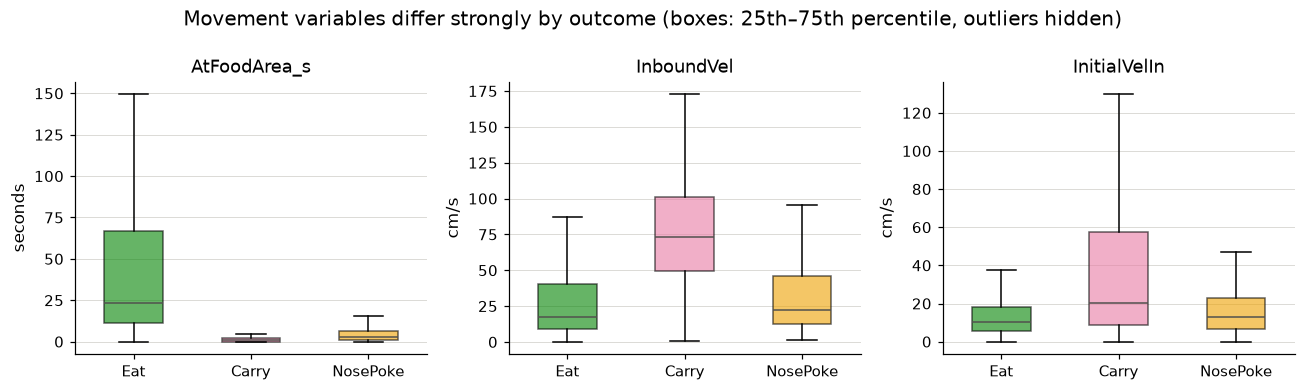

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, column in zip(axes, ["AtFoodArea_s", "InboundVel", "InitialVelIn"]):
    data_per_behavior = [movement_trials.loc[movement_trials["Behavior"] == b, column].dropna()
                         for b in ["Eat", "Carry", "NosePoke"]]
    box = ax.boxplot(data_per_behavior, tick_labels=["Eat", "Carry", "NosePoke"], showfliers=False,
                     patch_artist=True, widths=0.5, medianprops={"color": viz.NEUTRAL_DARK})
    for patch, behavior in zip(box["boxes"], ["Eat", "Carry", "NosePoke"]):
        patch.set_facecolor(viz.BEHAVIOR_COLORS[behavior])
        patch.set_alpha(0.6)
    ax.set_title(column)
    ax.set_ylabel(units[column])
fig.suptitle("Movement variables differ strongly by outcome (boxes: 25th–75th percentile, outliers hidden)")
fig.tight_layout()
viz.save_figure(fig, "01_movement_by_behavior")
plt.show()

**How to read the output:** time at the food area and the return (inbound) velocities differ strongly between Eat, Carry and NosePoke trials. This is largely *because of* the behavior: eating takes time at the food site, a nose-poke is brief, and a mouse carrying a pellet returns differently. A model given these variables would classify the outcome very well, but it would be describing the behavior after the fact, not predicting a decision. This is exactly the **target leakage** described in section 2.5, and it is why these variables are not used in any behavior model.

### 10.3 Movement per mouse: Control vs AD

**Goal:** compare the two groups at the level of the **mouse**. For each mouse we take the **median** of each variable over its trials. The median is robust to the long tails seen in 10.1. Each dot is then one mouse.

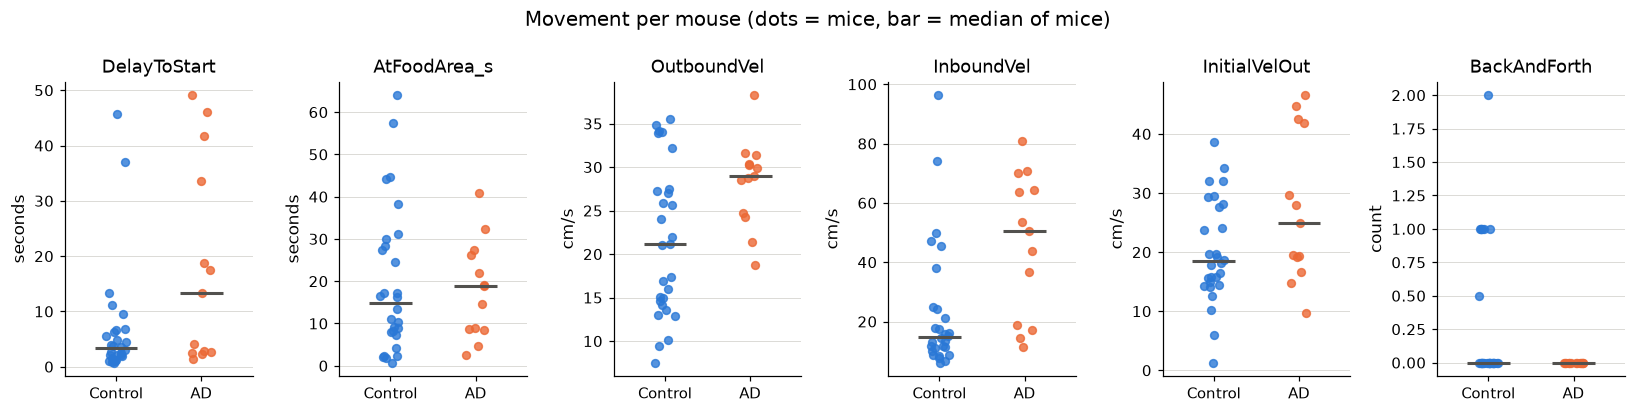

         DelayToStart  AtFoodArea_s  OutboundVel  InboundVel  InitialVelOut  BackAndForth
Status                                                                                   
Control           3.3          14.8         21.1        14.8           18.4           0.0
AD               13.4          18.9         28.9        50.5           24.9           0.0


In [33]:
mouse_medians = movement_trials.groupby(["Status", "Id"])[variables_to_plot].median().reset_index()

fig, axes = plt.subplots(1, len(variables_to_plot), figsize=(15, 3.8))
rng = np.random.default_rng(1)
for ax, column in zip(axes, variables_to_plot):
    for g_index, group in enumerate(viz.GROUP_ORDER):
        values = mouse_medians.loc[mouse_medians["Status"] == group, column]
        jitter = rng.uniform(-0.12, 0.12, size=len(values))
        ax.scatter(g_index + jitter, values, s=26, alpha=0.8, color=viz.GROUP_COLORS[group])
        ax.hlines(values.median(), g_index - 0.25, g_index + 0.25, color=viz.NEUTRAL_DARK, linewidth=2)
    ax.set_xticks(range(len(viz.GROUP_ORDER)))
    ax.set_xticklabels(viz.GROUP_ORDER)
    ax.set_xlim(-0.6, 1.6)
    ax.set_title(column)
    ax.set_ylabel(units[column])
fig.suptitle("Movement per mouse (dots = mice, bar = median of mice)")
fig.tight_layout()
viz.save_figure(fig, "01_movement_by_group")
plt.show()

print(mouse_medians.groupby("Status")[variables_to_plot].median().round(1).reindex(viz.GROUP_ORDER))

**How to read the output:**
* **Start latency:** AD mice split into two clear subgroups. Six AD mice leave home within ~1–4 s (like most Control mice), while the other seven take 13–49 s. Most Control mice are fast (group median 3.3 s). This bimodality matches the NoLeave pattern in section 7: a subset of AD mice is hesitant to leave home.
* **Inbound velocity:** AD mice return home faster on average (median of mice 50 vs 15 cm/s), but both groups vary widely, and the AD values also look bimodal.
* **Outbound velocity and time at food** differ less between the groups, and the values overlap a lot.
* **BackAndForth** is 0 for almost every mouse (the median trial has no back-and-forth movement), so its per-mouse median carries almost no information. A *mean* or a "fraction of trials with ≥ 1 back-and-forth" would be more useful.

**Caveats:** these variables are outcome-dependent (10.2). A group difference in inbound velocity could simply reflect *what* the mice did: carrying food home, or running back after a brief nose-poke. In notebook 03 we will therefore compare movement **within the same behavior** (e.g. inbound velocity on Eat trials only), so that differences in behavior mix do not masquerade as differences in movement.

### 10.4 Correlations between movement variables

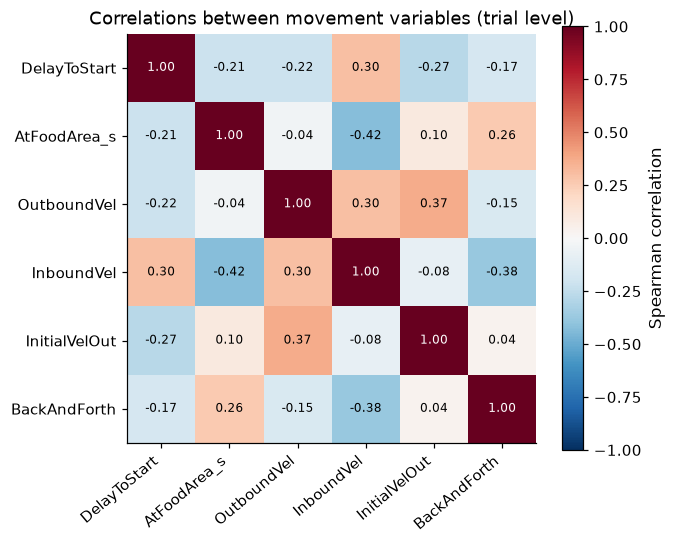

In [34]:
correlation = movement_trials[variables_to_plot].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(correlation.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables_to_plot)))
ax.set_xticklabels(variables_to_plot, rotation=40, ha="right")
ax.set_yticks(range(len(variables_to_plot)))
ax.set_yticklabels(variables_to_plot)
ax.grid(False)
for i in range(len(variables_to_plot)):
    for j in range(len(variables_to_plot)):
        value = correlation.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else "black")
fig.colorbar(image, ax=ax, label="Spearman correlation")
ax.set_title("Correlations between movement variables (trial level)")
viz.save_figure(fig, "01_movement_correlations")
plt.show()

**How to read the output:** we use **Spearman** correlation (based on ranks) because the variables are skewed and have outliers, which distort the ordinary (Pearson) correlation. All correlations are **weak to moderate** (|ρ| ≤ 0.42). The largest are time at food vs inbound velocity (−0.42: long stays go with slow returns) and outbound vs initial outbound velocity (0.37). No pair is so redundant that one variable must be dropped. Each variable carries partly separate information. (If two features were very strongly correlated, feature importance would be split arbitrarily between them, and we would keep only one.)

*Caveat:* trial-level correlations mix *within-mouse* and *between-mouse* variation.

## 11. Save the clean dataset

In [35]:
columns_to_save = [
    "Id", "Status", "Sex", "Date", "SessionId", "SessionNumber", "SessionInCondition",
    "TrialInSession", "Length", "Texture", "Condition", "PelletSize", "SizeCategory",
    "Behavior", "PrevBehavior",
    "DelayToStart", "AtFoodArea_s", "BackAndForth", "InitialVelOut", "OutboundVel", "InitialVelIn", "InboundVel",
    "RawRow",
]
clean = df[columns_to_save].sort_values("RawRow").reset_index(drop=True)

import os
os.makedirs("../data/processed", exist_ok=True)
clean.to_csv(PROCESSED_PATH, index=False)
print("Saved", clean.shape[0], "trials and", clean.shape[1], "columns to", PROCESSED_PATH)
clean.head()

Saved 5377 trials and 23 columns to ../data/processed/trials_clean.csv


,Id,Status,Sex,Date,SessionId,SessionNumber,SessionInCondition,TrialInSession,Length,Texture,Condition,PelletSize,SizeCategory,Behavior,PrevBehavior,DelayToStart,AtFoodArea_s,BackAndForth,InitialVelOut,OutboundVel,InitialVelIn,InboundVel,RawRow
0,3208,AD,Male,2020-11-20,1,1,1,1,short,soft,short-soft,1.0,small,Eat,SessionStart,7.500000,6.900000,0.0,133.247377,17.593750,10.899459,10.519737,0
1,3208,AD,Male,2020-11-20,1,1,1,2,short,soft,short-soft,2.0,small,NosePoke,Eat,1.800000,25.666667,0.0,53.673709,26.285714,11.454751,9.636364,1
2,3208,AD,Male,2020-11-20,1,1,1,3,short,soft,short-soft,3.0,large,NosePoke,NosePoke,4.166667,79.433333,1.0,68.734984,28.611111,12.967536,12.065217,2
3,3208,AD,Male,2020-11-20,1,1,1,4,short,soft,short-soft,4.0,large,NosePoke,NosePoke,4.400000,168.333333,2.0,35.208611,41.921053,5.718592,21.197368,3
4,3208,AD,Male,2020-11-23,2,2,2,1,short,soft,short-soft,2.0,small,NosePoke,SessionStart,4.366667,26.200000,4.0,66.408992,33.562500,7.054568,22.808219,4


## 12. Summary: what we learned and what it means for modeling

### Data facts
* **5,377 usable trials from 41 mice** (13 AD, 28 Control) in 1,409 sessions. Trials per mouse range from 26 to 239.
* `Trial` is a **date**. We reconstructed sessions (`SessionId`), session order (`SessionNumber`, `SessionInCondition`) and trial position (`TrialInSession`).
* Cleaning decisions: the two control cohorts merged into Control; the 5028 block (16 Mar – 12 Apr 2021) excluded; invalid NoLeave trials (with movement data) removed; PartialEat → Eat; NoApproach and unlabeled trials removed; negative delays → 0; velocity ceiling (200 cm/s) → missing; pellet sizes pooled into small/large. `PrevBehavior` was computed **before** removing any trials.

### Design issues that limit interpretation
1. **Unbalanced coverage:** 13 mice never received hard food.
2. **Block order:** conditions were presented in blocks with long-hard (almost always) last, so condition effects are partly confounded with experience.

### Behavioral patterns (descriptive, per-mouse averages)
* Eat dominates (~60 %), so the classes are **imbalanced**.
* **Pellet size** is the strongest task effect: large pellets are eaten less on the spot and are carried or nose-poked more.
* **AD mice show almost twice as much NoLeave**, concentrated in long-soft, the first change of condition for most mice. This effect comes from a subset of AD mice (6 of 10).
* Behaviors **repeat** from trial to trial, and NoLeave often follows Carry.
* NosePoke decreases over the first sessions of each block.

### Consequences for modeling
| Finding | What we will do |
|---|---|
| Most movement variables are measured during/after the outcome | Behavior models use task parameters, history and experience. Only the approach (`DelayToStart`, `InitialVelOut`) is added, and only for the food-site decision. Time at food, return speeds, `OutboundVel` and back-and-forth are not used as predictors |
| Large between-mouse variability, 13 AD mice | **Leave-mice-out** validation; report variability across held-out mice |
| Class imbalance, different rare classes per group | Balanced accuracy, macro-F1, per-class metrics; class weights inside the pipeline |
| Strong size effect, history effects, weak experience effects | Feature sets: task only → + history → + experience |
| Mouse is the unit for group classification | One row per mouse in notebook 03, with features defined for **every** mouse (despite unbalanced coverage) |